# Titanic: comparação de modelos e previsão

Projeto **exclusivamente educacional**, sem uso operacional. Este notebook completa o fluxo técnico com as funções de `src/`, também usadas no terminal. Não altera os notebooks anteriores.

**Pergunta:** conseguimos prever sobrevivência melhor que sempre escolher a classe majoritária? O critério didático de seleção será F1 dos sobreviventes, com outras métricas de apoio.

O teste **já foi consultado no baseline**. Nenhum resultado abaixo deve ser apresentado como uma avaliação independente. Os campos em branco da EDA continuam reservados às suas interpretações.

## 1. Ambiente e dados

Execute as células na ordem, com o kernel da `.venv`. Usamos somente o CSV local. A raiz é identificada para funcionar tanto a partir da pasta `notebooks` quanto da raiz do projeto.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Abra o notebook a partir da raiz do projeto ou da pasta notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline import RAW_FEATURES, SEED, create_features, read_passengers
from src.train import run_training
from sklearn.model_selection import train_test_split

data = read_passengers(ROOT / 'data/train.csv', training=True)
train, test = train_test_split(data, test_size=0.2, stratify=data['Survived'], random_state=SEED)
print(f'Treino: {len(train)} | Teste: {len(test)} | Semente: {SEED}')
print('O teste será usado só depois de fixar modelo, parâmetros e limiar.')

Treino: 712 | Teste: 179 | Semente: 42
O teste será usado só depois de fixar modelo, parâmetros e limiar.


## 2. Features e preparação

Criamos título, tamanho da família, indicador de passageiro sozinho, cabine registrada e logaritmo da tarifa. Essas operações usam somente a própria linha; não aprendem estatísticas da amostra.

O pipeline seleciona uma lista explícita de features. Target, rótulo textual, identificador e textos brutos não chegam ao estimador. A preparação aprende medianas, modas e categorias **dentro de cada partição**. Só a regressão logística padroniza as numéricas.

In [2]:
display(create_features(train[RAW_FEATURES]).head())
print('Entradas brutas:', RAW_FEATURES)

,Age,SibSp,Parch,FamilySize,IsAlone,HasCabin,LogFare,Pclass,Sex,Embarked,Title
692,NaN,0,0,1,1.0,0,4.051712,3,male,S,Mr
481,NaN,0,0,1,1.0,0,0.000000,2,male,S,Mr
527,NaN,0,0,1,1.0,1,5.406181,1,male,S,Mr
855,18.0,0,1,2,0.0,0,2.336987,3,female,S,Mrs
801,31.0,1,1,3,0.0,0,3.305054,2,female,S,Mrs


Entradas brutas: ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin', 'Embarked']


## 3. Treinar e registrar experimentos

A célula executa o mesmo fluxo de `python -m src.train`. Uma nova execução cria novos registros no MLflow e atualiza os arquivos de saída.

Comparamos dummy, regressão logística, árvore e XGBoost em CPU, com validação estratificada de cinco partições. As grades pequenas estão na função `model_specs` de `src/train.py`.

Selecionamos o maior F1 médio com limiar 0,50. Em empate numérico, preferimos logística, árvore e depois XGBoost. O dummy é uma referência e não disputa essa seleção.

Para o modelo escolhido, `cross_val_predict` gera probabilidades fora da partição. Testamos limiares de 0,20 a 0,80; o maior F1 vence, com desempate pela proximidade de 0,50 e depois pelo maior limiar. **Isso é ajuste interno:** os mesmos dados ajudam a escolher parâmetros e limiar, sem validação aninhada.

In [3]:
results = run_training(ROOT / 'data/train.csv')
reports = ROOT / 'reports'

Validação cruzada: dummy
Validação cruzada: logistica
Validação cruzada: arvore
Validação cruzada: xgboost
Modelo escolhido: logistica. Ajustando limiar somente no treino...
1. A sobrevivência no treino foi 38.3%; o baseline teve acurácia 0.615 no teste.
2. logistica venceu pela validação cruzada com F1 médio 0.766; complexidade não garante melhor resultado.
3. O limiar 0.45, escolhido somente no treino, resultou em precisão 0.775, recall 0.797 e F1 0.786 no teste (F1 com limiar 0,50: 0.794).
4. As maiores reduções médias de F1 por permutação envolveram Sex, Name, SibSp; são sinais preditivos conjuntos, não evidência causal ou políticas de resgate.
5. O teste já foi consultado, familiares podem compartilhar padrões e há dados ausentes; resultados são didáticos e não sustentam uso operacional.

Relatórios: C:\Users\brend\OneDrive\Documentos\titanic-survival-classification\titanic-survival-classification\reports
Modelo: C:\Users\brend\OneDrive\Documentos\titanic-survival-classification\t

## 4. Comparar modelos e investigar overfitting

Compare F1 de treino e validação. Uma distância grande sugere overfitting; o desvio entre partições mostra a estabilidade da validação. Um modelo mais complexo pode não vencer.

,model,train_f1,cv_f1,cv_f1_std,cv_accuracy,cv_precision,cv_recall,cv_roc_auc,parameters
0,dummy,0.0000,0.0000,0.0000,0.6166,0.0000,0.0000,0.5000,{}
1,logistica,0.7756,0.7663,0.0215,0.8230,0.7806,0.7547,0.8742,"{""model__C"": 10}"
2,arvore,0.7730,0.7649,0.0478,0.8245,0.8008,0.7438,0.8624,"{""model__max_depth"": 3, ""model__min_samples_le..."
3,xgboost,0.8985,0.7604,0.0293,0.8244,0.8026,0.7253,0.8912,"{""model__max_depth"": 3, ""model__n_estimators"":..."


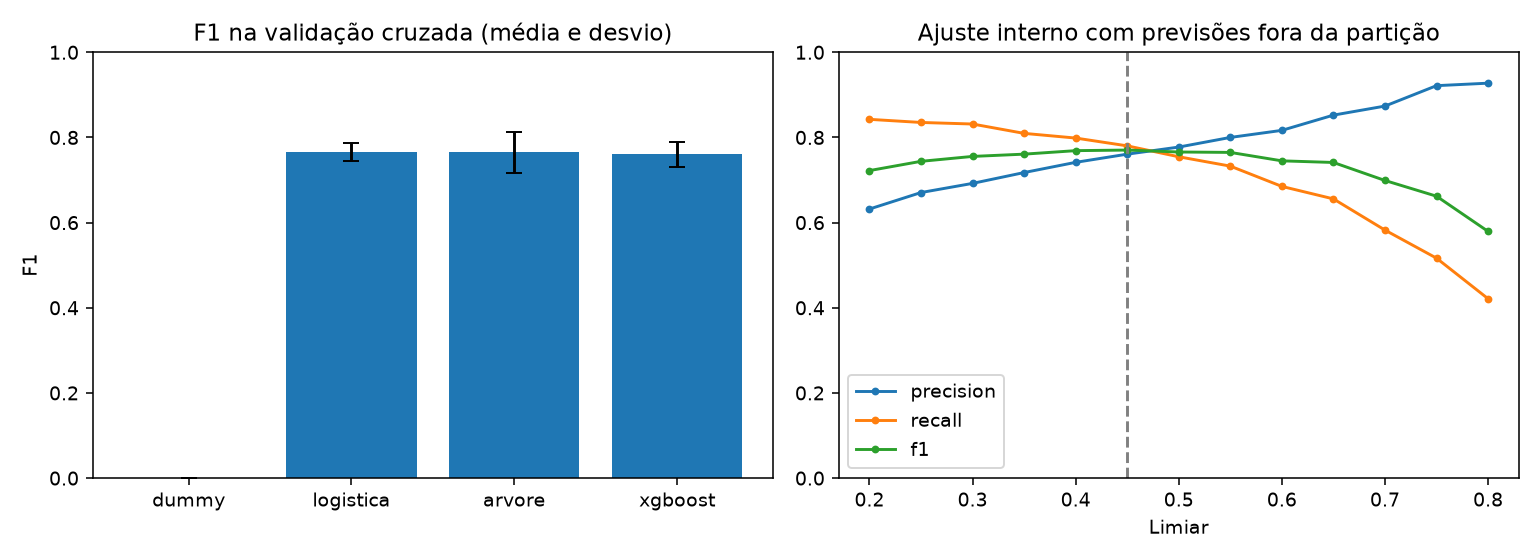

,threshold,accuracy,precision,recall,f1,roc_auc
0,0.20,0.7514,0.6319,0.8425,0.7221,0.8729
1,0.25,0.7795,0.6706,0.8352,0.7439,0.8729
2,0.30,0.7935,0.6921,0.8315,0.7554,0.8729
3,0.35,0.8048,0.7175,0.8095,0.7608,0.8729
4,0.40,0.8160,0.7415,0.7985,0.7690,0.8729
5,0.45,0.8216,0.7607,0.7802,0.7703,0.8729
6,0.50,0.8230,0.7774,0.7546,0.7658,0.8729
7,0.55,0.8272,0.8000,0.7326,0.7648,0.8729
8,0.60,0.8202,0.8166,0.6850,0.7450,0.8729
9,0.65,0.8244,0.8524,0.6557,0.7412,0.8729


In [4]:
comparison = pd.read_csv(reports / 'comparacao_modelos.csv')
display(comparison[['model', 'train_f1', 'cv_f1', 'cv_f1_std', 'cv_accuracy', 'cv_precision', 'cv_recall', 'cv_roc_auc', 'parameters']].round(4))
display(Image(filename=str(reports / 'validacao.png')))
display(pd.read_csv(reports / 'limiares.csv').round(4))

## 5. Avaliação didática e interpretação

Modelo, parâmetros e limiar já estão fixos. Comparamos baseline, limiar 0,50 e limiar escolhido nos mesmos 20%.

A matriz usa o limiar escolhido. A importância por permutação mostra a redução de F1 ao embaralhar cada coluna bruta, usando o limiar padrão 0,50. Ela é uma inspeção posterior: não alimenta a seleção. Features correlacionadas podem compartilhar importância; importância negativa ou pequena pode ser ruído. Não há interpretação causal.

,accuracy,precision,recall,f1,roc_auc
dummy,0.6145,0.0000,0.0000,0.0000,0.500
default_threshold,0.8436,0.8060,0.7826,0.7941,0.871
selected_threshold,0.8324,0.7746,0.7971,0.7857,0.871


Modelo: logistica | Limiar: 0.45
Avaliação didática em conjunto previamente consultado no baseline; não é uma estimativa independente.


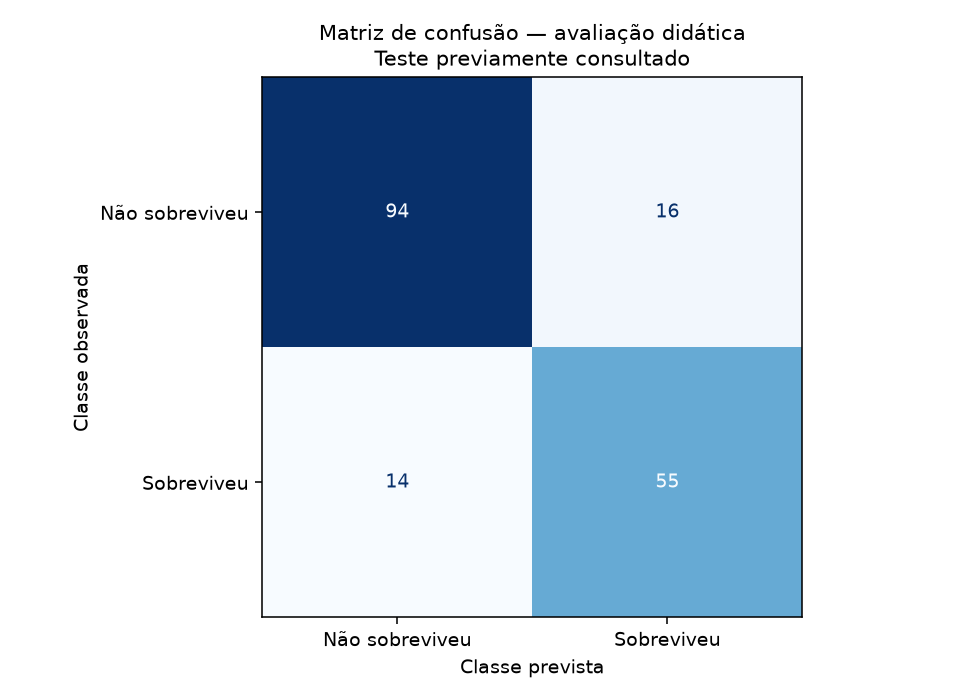

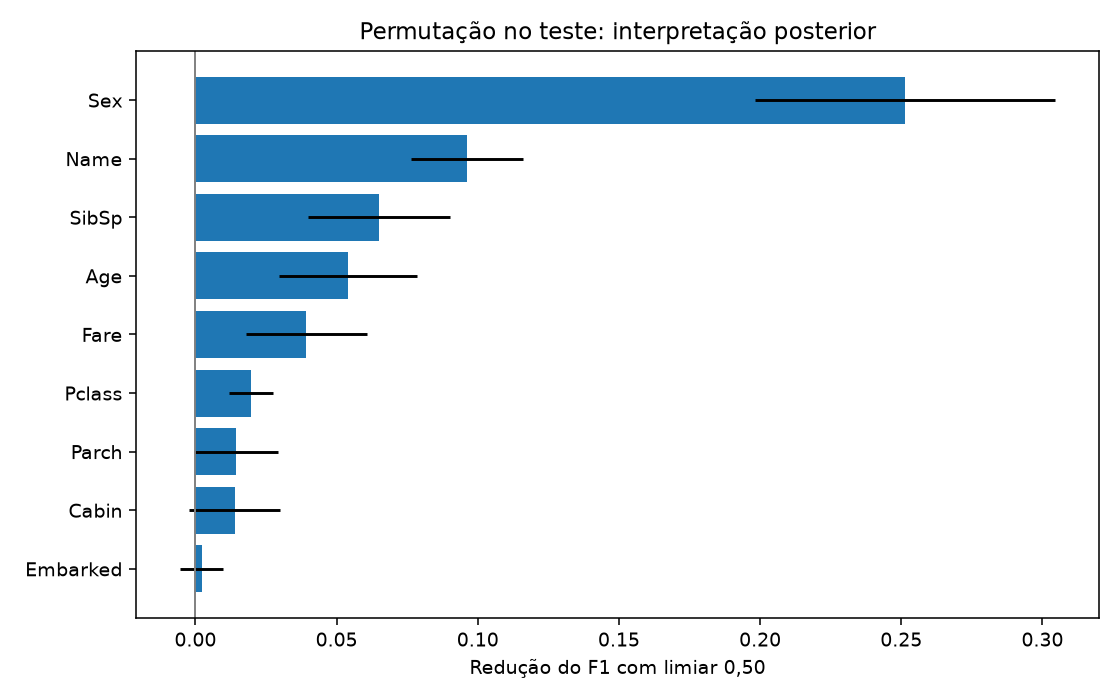

Mantemos o limiar escolhido no treino, mesmo se 0,50 tiver F1 maior no teste.


In [5]:
display(pd.DataFrame({label: results[label] for label in ['dummy', 'default_threshold', 'selected_threshold']}).T.round(4))
print('Modelo:', results['selected_model'], '| Limiar:', results['threshold'])
print(results['test_note'])
display(Image(filename=str(reports / 'matriz_confusao.png')))
display(Image(filename=str(reports / 'importancia.png')))
print('Mantemos o limiar escolhido no treino, mesmo se 0,50 tiver F1 maior no teste.')

## 6. Conclusões em cinco linhas

As frases são produzidas com os resultados medidos, sem prometer desempenho mínimo. Além do teste já consultado, existem dados ausentes, amostra histórica pequena e possível dependência entre familiares. Uma avaliação com novos dados independentes seria um próximo passo antes de qualquer discussão operacional.

In [6]:
display(Markdown((reports / 'conclusoes.md').read_text(encoding='utf-8')))

1. A sobrevivência no treino foi 38.3%; o baseline teve acurácia 0.615 no teste.
2. logistica venceu pela validação cruzada com F1 médio 0.766; complexidade não garante melhor resultado.
3. O limiar 0.45, escolhido somente no treino, resultou em precisão 0.775, recall 0.797 e F1 0.786 no teste (F1 com limiar 0,50: 0.794).
4. As maiores reduções médias de F1 por permutação envolveram Sex, Name, SibSp; são sinais preditivos conjuntos, não evidência causal ou políticas de resgate.
5. O teste já foi consultado, familiares podem compartilhar padrões e há dados ausentes; resultados são didáticos e não sustentam uso operacional.


## 7. Artefatos e previsão

O pacote salva o pipeline ajustado **somente nos 80%**, o limiar e as colunas de entrada. A previsão carrega o pacote sem ajustar novamente.

No terminal, na raiz:
```powershell
python -m src.predict --input data/test.csv
python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000
```
O CSV de previsão contém `PassengerId`, `ProbabilidadeSobrevivencia` e `Survived`. Campos ausentes e categorias novas são tratados pelo pipeline; colunas obrigatórias faltantes geram uma mensagem de erro.

No MLflow, abra http://127.0.0.1:5000 e selecione `titanic-aprendizado`: as execuções guardam parâmetros, métricas e artefatos locais. Não há deploy.

In [7]:
metadata = json.loads((reports / 'metadata.json').read_text(encoding='utf-8'))
print('Versões:', metadata['versions'])
print('SHA256 do CSV:', metadata['data_sha256'])
print('Modelo salvo:', (ROOT / 'models/titanic.joblib').is_file())
print('Relatórios:', sorted(path.name for path in reports.iterdir()))

Versões: {'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'mlflow': '3.18.0', 'joblib': '1.6.0'}
SHA256 do CSV: 7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f
Modelo salvo: True
Relatórios: ['busca_arvore.csv', 'busca_dummy.csv', 'busca_logistica.csv', 'busca_xgboost.csv', 'comparacao_modelos.csv', 'conclusoes.md', 'importancia.csv', 'importancia.png', 'limiares.csv', 'matriz_confusao.png', 'metadata.json', 'metricas.json', 'validacao.png']
